<div align="center">

# МГТУ им. Н.Э. Баумана

### Факультет «Информатика и системы управления» (ИУ)
### Кафедра «Информационные системы и телекоммуникации» (ИУ3)

# Отчёт по лабораторной работе №9
## по курсу «Технологии машинного обучения»

### Тема: Анализ и прогнозирование временного ряда

</div>

---

**Выполнил:** Суржиков Лев Алексеевич

**Группа:** ИУ3С-51Б

**Проверил:** Ю.Е. Гапанюк

## 1. Описание задания

**Цель работы:** изучение основных методов анализа и прогнозирования временных рядов.

**Задание:**
1. Выбрать набор данных для решения задачи прогнозирования временного ряда.
2. Визуализировать временной ряд и его основные характеристики.
3. Разделить временной ряд на обучающую и тестовую выборку.
4. Выполнить прогнозирование следующими методами: одним из авторегрессионных методов (ARMA, ARIMA, ...); методом символьной регрессии; двумя методами из семейства МГУА (один линейный COMBI/MULTI и один нелинейный MIA/RIA) с использованием библиотеки gmdh.
5. Визуализировать тестовую выборку и каждый из прогнозов.
6. Оценить качество прогноза в каждом случае с помощью подходящей метрики.
7. (Дополнительно) оставить обратную связь по использованию библиотеки gmdh.

Ссылка на постановку задания: https://github.com/ugapanyuk/courses_current/wiki/LAB_TMO_TIMESERIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import warnings

import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from gplearn.genetic import SymbolicRegressor
import gmdh

matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings("ignore")

BLUE_DARK = "#1B3B6F"
BLUE = "#3B6EA5"
BLUE_LIGHT = "#8FB8D9"
RED_DARK = "#7A1F2B"
RED = "#B23A48"
RED_LIGHT = "#E0949C"

## 2. Набор данных

Используется встроенный набор данных библиотеки statsmodels — **содержание углекислого газа (CO₂) в атмосфере** по измерениям обсерватории Мауна-Лоа (США), ppm. Исходные данные недельные (1958–2001 гг.); для прогнозирования переводим их в **месячные** значения (среднее за месяц, редкие пропуски заполняем интерполяцией). Получается временной ряд из 526 месячных значений с выраженным трендом и годовой сезонностью.

In [2]:
co2 = sm.datasets.co2.load_pandas().data["co2"]
series = co2.resample("MS").mean().interpolate()   # месячный ряд
print("Длина ряда:", len(series))
print("Период:", series.index[0].date(), "—", series.index[-1].date())
print("Пропусков:", series.isna().sum())
series.head()

Длина ряда: 526
Период: 1958-03-01 — 2001-12-01
Пропусков: 0


1958-03-01    316.100000
1958-04-01    317.200000
1958-05-01    317.433333
1958-06-01    316.529167
1958-07-01    315.625000
Freq: MS, Name: co2, dtype: float64

## 3. Визуализация временного ряда и его характеристик

### 3.1. Ряд и скользящие статистики

Скользящее среднее (окно 12 месяцев) показывает тренд, скользящее стандартное отклонение — изменчивость.

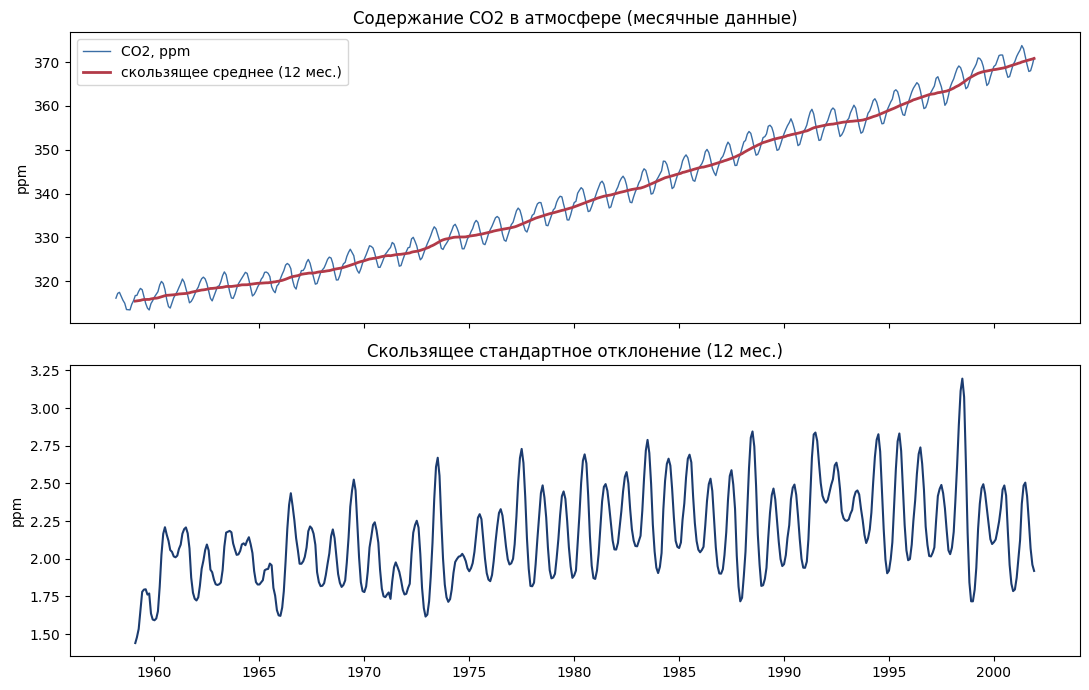

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(series, color=BLUE, linewidth=1, label="CO2, ppm")
axes[0].plot(series.rolling(12).mean(), color=RED, linewidth=2, label="скользящее среднее (12 мес.)")
axes[0].set_ylabel("ppm")
axes[0].set_title("Содержание CO2 в атмосфере (месячные данные)")
axes[0].legend()
axes[1].plot(series.rolling(12).std(), color=BLUE_DARK)
axes[1].set_ylabel("ppm")
axes[1].set_title("Скользящее стандартное отклонение (12 мес.)")
plt.tight_layout()
plt.show()

### 3.2. Разложение ряда на тренд, сезонность и остаток

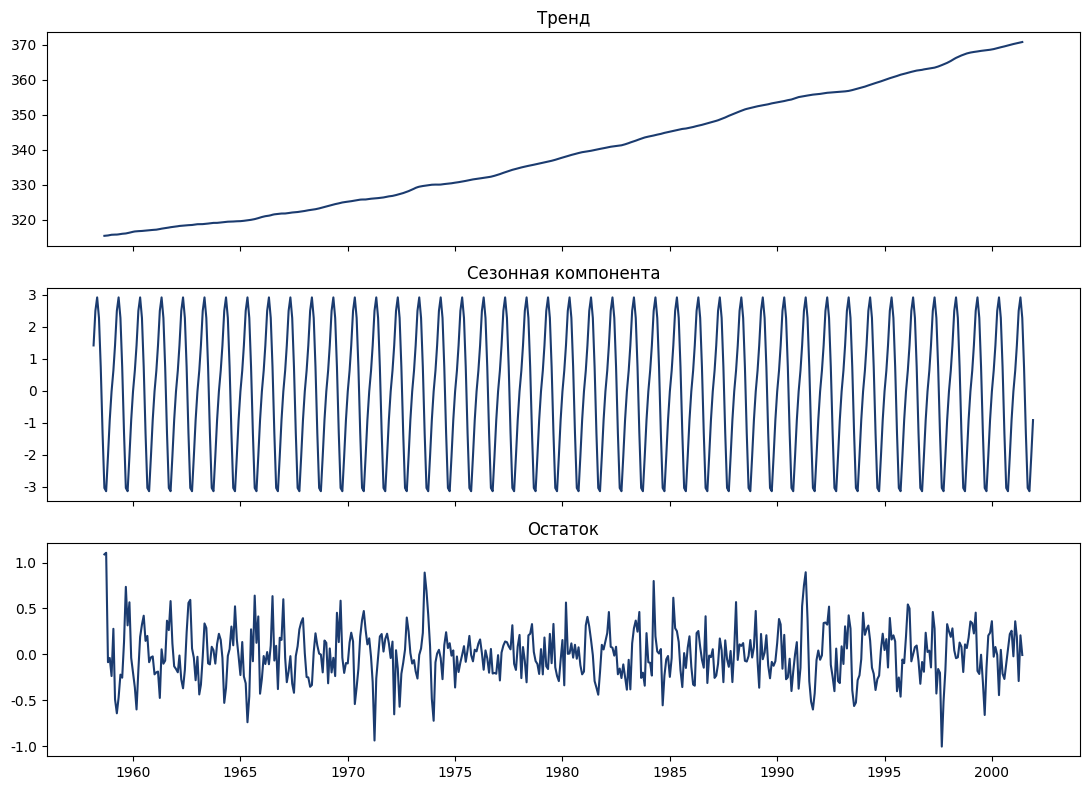

Размах сезонной компоненты: от -3.14 до 2.92 ppm


In [4]:
dec = seasonal_decompose(series, model="additive", period=12)
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, (name, part) in zip(axes, [("Тренд", dec.trend), ("Сезонная компонента", dec.seasonal), ("Остаток", dec.resid)]):
    ax.plot(part, color=BLUE_DARK)
    ax.set_title(name)
plt.tight_layout()
plt.show()
print("Размах сезонной компоненты: от %.2f до %.2f ppm" % (dec.seasonal.min(), dec.seasonal.max()))

### 3.3. Стационарность и автокорреляция

Проверяем стационарность тестом Дики–Фуллера (ADF): если p-value больше 0,05, ряд нестационарен. Затем смотрим тот же тест для ряда первых разностей и графики автокорреляции.

In [5]:
def adf_report(name, x):
    stat, p = adfuller(x)[:2]
    print(f"{name}: статистика {stat:.3f}, p-value {p:.4f} ->", "стационарен" if p < 0.05 else "нестационарен")

adf_report("Исходный ряд", series)
adf_report("Первые разности", series.diff().dropna())

Исходный ряд: статистика 2.233, p-value 0.9989 -> нестационарен
Первые разности: статистика -4.752, p-value 0.0001 -> стационарен


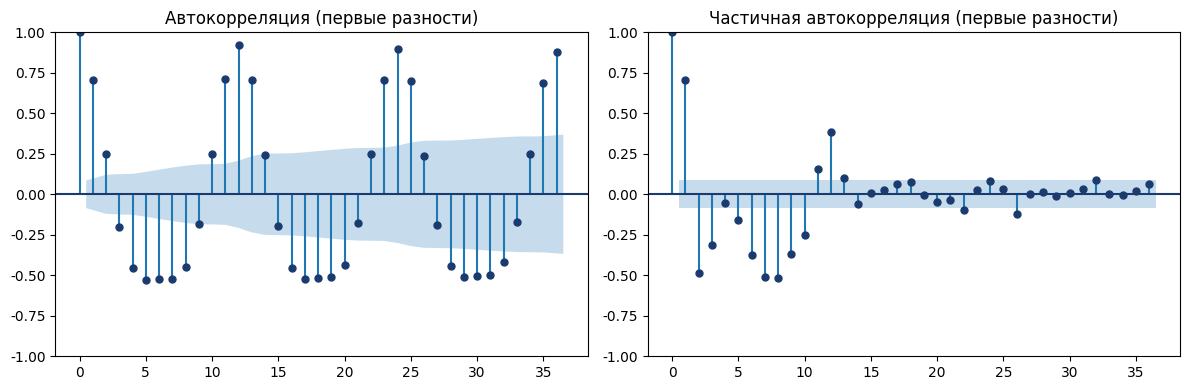

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(series.diff().dropna(), lags=36, ax=axes[0], color=BLUE_DARK)
plot_pacf(series.diff().dropna(), lags=36, ax=axes[1], color=BLUE_DARK, method="ywm")
axes[0].set_title("Автокорреляция (первые разности)")
axes[1].set_title("Частичная автокорреляция (первые разности)")
plt.tight_layout()
plt.show()

## 4. Разделение на обучающую и тестовую выборки

Для временного ряда нельзя перемешивать данные: тестовой берём **последние 36 месяцев** (3 года), остальное — обучающая выборка. Все модели прогнозируют сразу весь тестовый период (36 шагов вперёд).

Обучающая выборка: 490 месяцев, до 1998-12-01
Тестовая выборка: 36 месяцев, с 1999-01-01


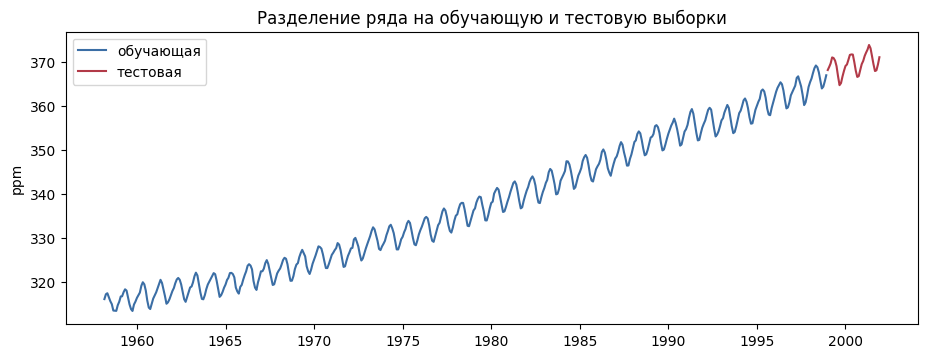

In [7]:
test_size = 36
train, test = series.iloc[:-test_size], series.iloc[-test_size:]
print("Обучающая выборка:", len(train), "месяцев, до", train.index[-1].date())
print("Тестовая выборка:", len(test), "месяцев, с", test.index[0].date())

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(train, color=BLUE, label="обучающая")
ax.plot(test, color=RED, label="тестовая")
ax.set_title("Разделение ряда на обучающую и тестовую выборки")
ax.set_ylabel("ppm")
ax.legend()
plt.show()

## 5. Прогнозирование

Метрики качества: **MAE** (средняя абсолютная ошибка, в ppm), **RMSE** (корень из среднеквадратичной ошибки) и **MAPE** (средняя абсолютная процентная ошибка).

### 5.1. Авторегрессионный метод: сезонная модель ARIMA

Используем сезонную модель ARIMA (SARIMA) порядка (1,1,1)(0,1,1)₁₂: одно дифференцирование (убирает тренд), сезонное дифференцирование с периодом 12 (убирает годовую сезонность), по одному члену авторегрессии и скользящего среднего. Порядок выбран по графикам автокорреляции.

In [8]:
def metrics(y_true, y_pred):
    err = np.asarray(y_true) - np.asarray(y_pred)
    return {"MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE, %": np.mean(np.abs(err / np.asarray(y_true))) * 100}

sarima = SARIMAX(train, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
pred_arima = sarima.forecast(test_size)
results = {"SARIMA": metrics(test, pred_arima)}
print(sarima.summary().tables[1])
print({k: round(v, 3) for k, v in results["SARIMA"].items()})

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2840      0.111      2.568      0.010       0.067       0.501
ma.L1         -0.6049      0.095     -6.350      0.000      -0.792      -0.418
ma.S.L12      -0.8524      0.029    -29.351      0.000      -0.909      -0.796
sigma2         0.0938      0.006     15.626      0.000       0.082       0.106
{'MAE': 0.969, 'RMSE': 1.058, 'MAPE, %': 0.262}


### 5.2. Подготовка признаков для моделей на основе лагов

Метод символьной регрессии и методы МГУА работают с таблицей «признаки → целевое значение». Превращаем ряд в такую таблицу: признаки — 12 предыдущих значений (лагов), целевое значение — следующее. Чтобы убрать тренд, строим модели для **первых разностей** ряда (изменение за месяц), а прогноз потом суммируем обратно в уровни ряда. Многошаговый прогноз получаем рекурсивно: предсказанное значение добавляем в историю и предсказываем следующее.

In [9]:
lags = 12
diff_train = np.diff(train.values)                          # первые разности обучающей части
X, Y = gmdh.time_series_transformation(diff_train, lags)    # лаги -> следующее значение
print("Матрица признаков:", X.shape, " Целевые значения:", Y.shape)

def forecast_recursive(model, history_diff, steps, last_level):
    """Рекурсивный прогноз: предсказываем разность, добавляем в историю, идём дальше."""
    window = list(history_diff[-lags:])
    diffs = []
    for _ in range(steps):
        d = float(np.ravel(model.predict(np.array(window[-lags:]).reshape(1, -1)))[0])
        diffs.append(d)
        window.append(d)
    return last_level + np.cumsum(diffs)

Матрица признаков: (477, 12)  Целевые значения: (477,)


### 5.3. Метод символьной регрессии

Символьная регрессия (gplearn) эволюционным способом подбирает **формулу** (из операций сложения, вычитания и умножения), которая лучше всего предсказывает следующее значение по лагам.

In [10]:
sym = SymbolicRegressor(population_size=2000, generations=30, function_set=("add", "sub", "mul"),
                        parsimony_coefficient=0.001, metric="mse", random_state=1, n_jobs=1)
sym.fit(X, Y)
print("Найденная формула:", sym._program)

pred_sym = forecast_recursive(sym, diff_train, test_size, train.values[-1])
results["Символьная регрессия"] = metrics(test, pred_sym)
print({k: round(v, 3) for k, v in results["Символьная регрессия"].items()})

Найденная формула: mul(X0, 0.960)
{'MAE': 2.17, 'RMSE': 2.417, 'MAPE, %': 0.587}


### 5.4. Методы МГУА (библиотека gmdh)

Метод группового учёта аргументов (МГУА) строит модель из набора простых полиномов и отбирает лучшие по внешнему критерию (на отложенной части данных). Берём два метода:
- **COMBI** — линейный комбинаторный метод: перебирает комбинации лагов и строит линейную модель;
- **RIA** — нелинейный (полиномиальный) метод: строит многоуровневую сеть квадратичных полиномов.

In [11]:
combi = gmdh.Combi()
combi.fit(X, Y)
pred_combi = forecast_recursive(combi, diff_train, test_size, train.values[-1])
results["МГУА: COMBI (линейный)"] = metrics(test, pred_combi)
print({k: round(v, 3) for k, v in results["МГУА: COMBI (линейный)"].items()})

{'MAE': 0.961, 'RMSE': 1.037, 'MAPE, %': 0.26}


In [12]:
ria = gmdh.Ria()
ria.fit(X, Y)
pred_ria = forecast_recursive(ria, diff_train, test_size, train.values[-1])
results["МГУА: RIA (нелинейный)"] = metrics(test, pred_ria)
print({k: round(v, 3) for k, v in results["МГУА: RIA (нелинейный)"].items()})

{'MAE': 0.562, 'RMSE': 0.64, 'MAPE, %': 0.152}


Для полноты проверим и два оставшихся метода МГУА (MULTI — линейный, MIA — нелинейный), чтобы убедиться, что выбор COMBI и RIA не случаен.

In [13]:
extra = {}
for name, model in [("MULTI (линейный)", gmdh.Multi()), ("MIA (нелинейный)", gmdh.Mia())]:
    model.fit(X, Y)
    extra[name] = metrics(test, forecast_recursive(model, diff_train, test_size, train.values[-1]))
pd.DataFrame(extra).T.round(3)

,MAE,RMSE,"MAPE, %"
MULTI (линейный),0.526,0.604,0.143
MIA (нелинейный),1.235,1.332,0.334


## 6. Визуализация прогнозов и сравнение качества

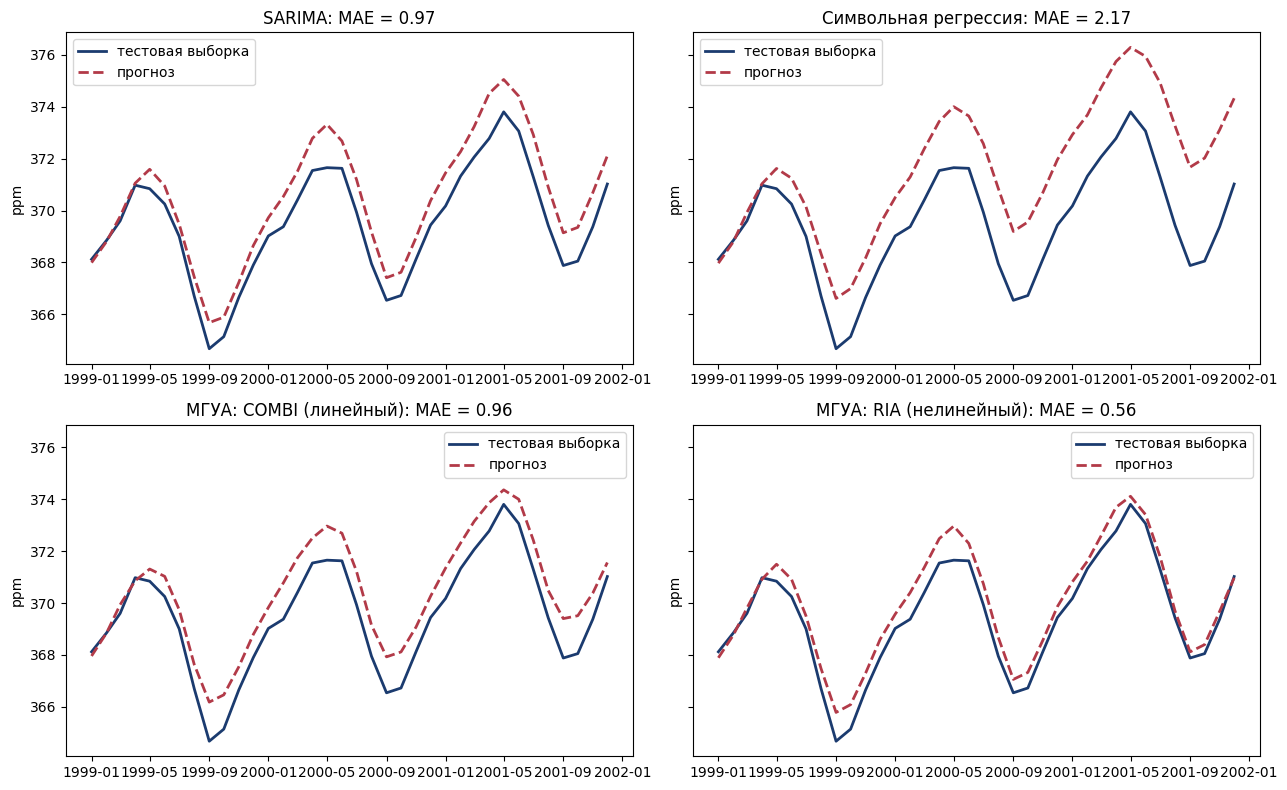

In [14]:
forecasts = {"SARIMA": pred_arima,
             "Символьная регрессия": pred_sym,
             "МГУА: COMBI (линейный)": pred_combi,
             "МГУА: RIA (нелинейный)": pred_ria}
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for ax, (name, fc) in zip(axes.ravel(), forecasts.items()):
    ax.plot(test.index, test.values, color=BLUE_DARK, linewidth=2, label="тестовая выборка")
    ax.plot(test.index, fc, color=RED, linewidth=2, linestyle="--", label="прогноз")
    ax.set_title(f"{name}: MAE = {results[name]['MAE']:.2f}")
    ax.set_ylabel("ppm")
    ax.legend()
plt.tight_layout()
plt.show()

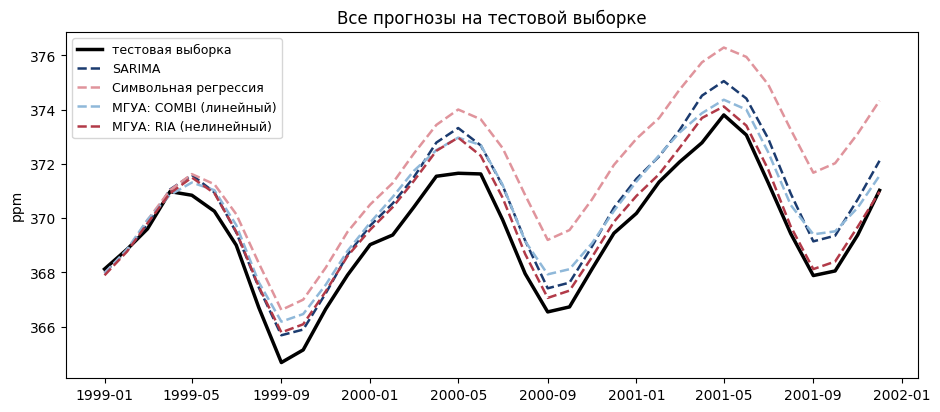

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(test.index, test.values, color="black", linewidth=2.5, label="тестовая выборка")
for (name, fc), c in zip(forecasts.items(), [BLUE_DARK, RED_LIGHT, BLUE_LIGHT, RED]):
    ax.plot(test.index, fc, linewidth=1.8, linestyle="--", color=c, label=name)
ax.set_title("Все прогнозы на тестовой выборке")
ax.set_ylabel("ppm")
ax.legend(fontsize=9)
plt.show()

In [16]:
table = pd.DataFrame(results).T.sort_values("MAE")
table.round(3)

,MAE,RMSE,"MAPE, %"
МГУА: RIA (нелинейный),0.562,0.640,0.152
МГУА: COMBI (линейный),0.961,1.037,0.260
SARIMA,0.969,1.058,0.262
Символьная регрессия,2.170,2.417,0.587


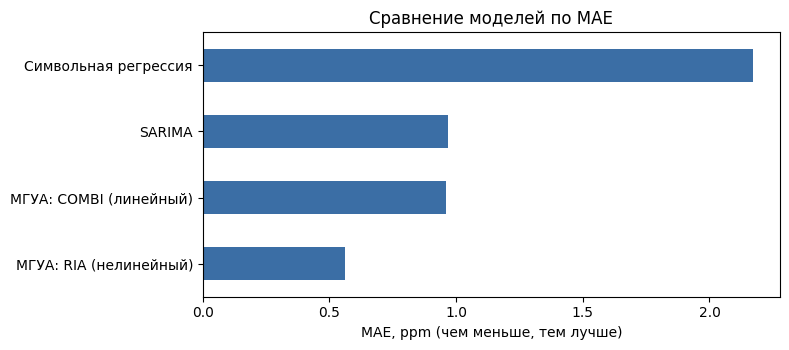

In [17]:
ax = table["MAE"].sort_values().plot(kind="barh", color=BLUE, figsize=(8, 3.6))
ax.set_xlabel("MAE, ppm (чем меньше, тем лучше)")
ax.set_title("Сравнение моделей по MAE")
plt.tight_layout()
plt.show()

## 7. Выводы

1. Для прогнозирования выбран временной ряд содержания CO₂ в атмосфере (Мауна-Лоа, месячные данные, 526 значений). Ряд нестационарен (тест Дики–Фуллера, p-value 0,9989), а ряд первых разностей стационарен (p-value 0,0001). Разложение показало рост тренда и годовую сезонность с размахом примерно от −3,1 до +2,9 ppm.
2. Тестовой выборкой взяты последние 36 месяцев, обучающей — 490 месяцев. Все модели прогнозировали сразу весь тестовый период (36 шагов вперёд).
3. Лучший результат среди обязательных методов у **нелинейного метода МГУА RIA**: MAE 0,562 ppm, RMSE 0,640, MAPE 0,15 %. Линейный метод МГУА **COMBI** (MAE 0,961) и сезонная модель **SARIMA** (MAE 0,969) показали почти одинаковое качество — в обоих случаях это линейные модели по предыдущим значениям. Хуже всех **символьная регрессия** (MAE 2,170, MAPE 0,59 %).
4. Символьная регрессия подобрала слишком простую формулу `0,960·X0` (следующее изменение ряда примерно равно предыдущему). Такая формула минимизирует ошибку на один шаг, но не учитывает годовую сезонность, поэтому при многошаговом рекурсивном прогнозе накапливается систематическая ошибка.
5. На графиках видно, что все модели хорошо повторяют форму сезонных колебаний, но прогноз во всех случаях расположен выше фактических значений: в тестовые годы рост ряда замедлился по сравнению с обучающими, и модели продолжили прежний тренд. Лучше всех с этим справилась модель RIA.
6. Дополнительная проверка двух других методов МГУА показала: линейный MULTI дал MAE 0,526 (чуть лучше RIA), нелинейный MIA — 1,235 (хуже RIA). Разница между RIA и MULTI мала, поэтому нельзя утверждать, что нелинейность обязательно помогает: качество зависит от конкретного метода и настроек. Оценка получена на одной тестовой выборке и носит иллюстративный характер.
7. Общий вывод: для рядов с трендом и сезонностью хорошо подходят авторегрессионные модели и методы МГУА, использующие лаги; символьная регрессия в простой постановке без сезонного признака справляется хуже.
8. Замечания по библиотеке gmdh (обратная связь по заданию): а) на PyPI для macOS нет готовой сборки (есть только Windows и Linux), поэтому на Mac библиотека устанавливается только сборкой из исходников и требует установленных cmake и Boost (включая компоненты system, thread, filesystem, json, chrono); б) при использовании NumPy версии 2.x (macOS, Apple Silicon, Python 3.9) вызовы `gmdh.time_series_transformation` и метода `fit` аварийно завершаются с ошибкой «Segmentation fault» без сообщения; при NumPy 1.26 всё работает. Это нужно отметить в документации (ограничение версий).
